# Foundations of Generative AI (ICT4403)
## Assignment 2: Autoregressive Text Generation

In this assignment, I compare Simple RNN, Bidirectional RNN, LSTM and GRU models for word-level next-word prediction on WikiText-2 using PyTorch.

**Experiment status:** I have revised the implementation to select best-validation checkpoints, evaluate the test split and generate without artificial padding. This version has not yet completed training on WikiText-2. My initial measured results are in `results/initial_run/` and are discussed separately in the repository README.

I use eight epochs per model, three identical prompts, temperatures 0.5, 1.0 and 1.3, and three sampling seeds. The notebook is self-contained. For execution, I use a fresh Kaggle GPU session with Internet enabled.

In [2]:
%pip install -q 'datasets>=2.14.0' 'pandas>=1.5.0' 'numpy>=1.23.0' 'matplotlib>=3.6.0' 'tabulate>=0.9.0'
import os
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
# Kaggle supplies PyTorch. Start a fresh kernel before running this setup.


Note: you may need to restart the kernel to use updated packages.


## Dataset and experimental method

I use [Salesforce/wikitext](https://huggingface.co/datasets/Salesforce/wikitext), configuration `wikitext-2-raw-v1`. I select the first 8,000 training and 1,500 validation entries with stripped length greater than 20 characters. These are ordered subsets, not all non-empty paragraphs. I lowercase and tokenize words plus `.,!?;`, then concatenate entries within each split. Contexts can cross entry boundaries but never split boundaries. I build the vocabulary from training only, using up to 9,998 tokens plus `<pad>` and `<unk>`.

I construct each input–target pair as `ids[start:start+30] -> ids[start+30]`, with stride 3. For a length-three illustration, `the army was -> deployed`. The target is excluded from the context and training inputs have no padding. I compute dataset sizes and unknown-token rates directly from the pipeline. For final evaluation, I use all official test entries with the same tokenizer, stride and training vocabulary, without an entry filter or cap. I do not use test data for model selection.

I use embedding size 256, hidden size 256 per direction, two recurrent layers, dropout 0.2, Adam at 0.001, batch size 128, gradient clipping 1.0 and eight epochs for every model. My BiRNN concatenates the final forward and backward hidden states of the last layer, both restricted to observed context. LSTM uses three gates plus a candidate update; GRU uses two gates plus a candidate update. Equal hidden sizes do not imply equal parameter counts.

I seed Python, NumPy and PyTorch and initialize each model's independent DataLoader generator with the same seed. This controls batch order without implying identical weights across architectures. I retain partial batches, weight average loss by target count, and select checkpoints only by validation loss. I use selected weights for final test evaluation and generation while keeping final-epoch validation results separate.

I measure training time separately from fit time, which also includes validation, checkpoint/history writes and logging. CUDA synchronization defines timing boundaries. I record versions, device and configuration. One training seed is a practical default, but cannot establish statistical significance or ranking stability.

In [4]:
"""Word-level next-word prediction and recurrent model comparison on WikiText-2."""
import json
import math
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import platform
import random
import re
import shutil
import time
from collections import Counter
from pathlib import Path

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

MODELS = ['SimpleRNN', 'BiRNN', 'LSTM', 'GRU']
PROMPTS = ['the history of the united states began with',
           'during the second world war the army was',
           'the album received positive reviews from music critics']
DEFAULT_CONFIG = dict(dataset='Salesforce/wikitext', dataset_config='wikitext-2-raw-v1',
    train_entries=8000, validation_entries=1500, min_chars=20, vocab_limit=10000,
    seq_len=30, stride=3, embed_dim=256, hidden_dim=256, num_layers=2,
    dropout=0.2, batch_size=128, epochs=8, lr=0.001, clip=1.0,
    training_seeds=[42], sampling_seeds=[101, 202, 303],
    temperatures=[0.5, 1.0, 1.3], new_tokens=25, prompts=PROMPTS)

def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, allow_nan=False), encoding='utf-8')

def tokenize(text):
    return re.findall(r'\b\w+\b|[.,!?;]', text.lower())

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True)

class Windows(Dataset):
    def __init__(self, ids, seq_len, stride=3):
        self.ids = torch.tensor(ids, dtype=torch.long)
        self.seq_len = seq_len
        self.starts = range(0, max(0, len(ids)-seq_len), stride)

    def __len__(self):
        return len(self.starts)

    def __getitem__(self, i):
        start = self.starts[i]
        return self.ids[start:start+self.seq_len], self.ids[start+self.seq_len]

def prepare_data(raw, config):
    """Official splits stay separate; test has no entry filter or subset cap."""
    tokens, stats = {}, {}
    for split in ['train', 'validation', 'test']:
        entries = list(raw[split]['text'])
        eligible = entries if split == 'test' else [s for s in entries if len(s.strip()) > config['min_chars']]
        cap = config.get(split+'_entries') if split != 'test' else None
        selected = eligible[:cap] if cap is not None else eligible
        tokens[split] = [w for s in selected for w in tokenize(s)]
        stats[split] = dict(raw_entries=len(entries), eligible_entries=len(eligible),
                            selected_entries=len(selected), tokens=len(tokens[split]))
    itos = ['<pad>', '<unk>'] + [w for w, _ in Counter(tokens['train']).most_common(config['vocab_limit']-2)]
    stoi = {w:i for i,w in enumerate(itos)}
    datasets = {}
    for split, words in tokens.items():
        ids = [stoi.get(w, 1) for w in words]
        datasets[split] = Windows(ids, config['seq_len'], config['stride'])
        stats[split].update(sequences=len(datasets[split]),
                            unknown_tokens=ids.count(1), unknown_rate=ids.count(1)/max(1,len(ids)))
        if not len(datasets[split]):
            raise ValueError(f'No windows in {split}')
    stats.update(vocabulary_size=len(itos), dataset=config['dataset'],
                 dataset_config=config['dataset_config'],
                 fingerprints={s:getattr(raw[s], '_fingerprint', None) for s in tokens})
    return datasets, itos, stats

class LanguageModel(nn.Module):
    def __init__(self, kind, vocab_size, config):
        super().__init__()
        self.kind = kind
        self.embedding = nn.Embedding(vocab_size, config['embed_dim'])
        self.dropout = nn.Dropout(config['dropout'])
        recurrent = {'SimpleRNN':nn.RNN, 'BiRNN':nn.RNN, 'LSTM':nn.LSTM, 'GRU':nn.GRU}[kind]
        self.rnn = recurrent(config['embed_dim'], config['hidden_dim'],
            num_layers=config['num_layers'], batch_first=True, bidirectional=kind=='BiRNN',
            dropout=config['dropout'] if config['num_layers']>1 else 0)
        self.fc = nn.Linear(config['hidden_dim']*(2 if kind=='BiRNN' else 1), vocab_size)

    def forward(self, x):
        _, hidden = self.rnn(self.dropout(self.embedding(x)))
        if self.kind == 'LSTM':
            hidden = hidden[0]
        final = torch.cat((hidden[-2], hidden[-1]), dim=1) if self.kind=='BiRNN' else hidden[-1]
        return self.fc(self.dropout(final))

def loader(dataset, config, seed, training=False):
    return DataLoader(dataset, batch_size=config['batch_size'], shuffle=training,
                      drop_last=False, num_workers=0,
                      generator=torch.Generator().manual_seed(seed))

def synchronize(device):
    if device.type == 'cuda':
        torch.cuda.synchronize(device)

def pass_epoch(model, batches, device, optimizer=None, clip=1.0):
    model.train(optimizer is not None)
    total_loss, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(optimizer is not None):
        for x,y in batches:
            x,y = x.to(device), y.to(device)
            if optimizer is not None:
                optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = nn.functional.cross_entropy(logits, y)
            if optimizer is not None:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), clip)
                optimizer.step()
            total_loss += loss.item()*y.numel()
            correct += (logits.argmax(-1)==y).sum().item()
            count += y.numel()
    loss = total_loss/count
    if not math.isfinite(loss):
        raise RuntimeError('Non-finite loss; this run cannot be reported as completed')
    return dict(loss=loss, perplexity=math.exp(loss), accuracy_pct=100*correct/count, targets=count)

def restore(path, kind, itos, config, device):
    model = LanguageModel(kind, len(itos), config).to(device)
    model.load_state_dict(torch.load(path, map_location=device, weights_only=True))
    return model.eval()

def fit(kind, datasets, itos, config, seed, directory, device):
    seed_all(seed)
    model = LanguageModel(kind, len(itos), config).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config['lr'])
    train = loader(datasets['train'], config, seed, True)
    val = loader(datasets['validation'], config, seed)
    checkpoint = directory/f'{kind}-seed{seed}-best.pt'
    history, best_loss, best_epoch = [], float('inf'), None
    synchronize(device)
    start = time.perf_counter()
    for epoch in range(1, config['epochs']+1):
        synchronize(device)
        train_start = time.perf_counter()
        tr = pass_epoch(model, train, device, optimizer, config['clip'])
        synchronize(device)
        train_seconds = time.perf_counter()-train_start
        va = pass_epoch(model, val, device)
        if va['loss'] < best_loss:
            best_loss, best_epoch = va['loss'], epoch
            torch.save(model.state_dict(), checkpoint)
        row = dict(model=kind, training_seed=seed, epoch=epoch, train_seconds=train_seconds,
                   **{'train_'+k:v for k,v in tr.items()}, **{'validation_'+k:v for k,v in va.items()})
        history.append(row)
        write_json(directory/f'{kind}-seed{seed}-history.json', history)
        print(f'{kind} seed={seed} epoch={epoch} validation PPL={va["perplexity"]:.2f}', flush=True)
    synchronize(device)
    elapsed = time.perf_counter()-start
    parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
    # Preserve final-epoch validation separately; final weights are not used for test or samples.
    del optimizer, model
    best = restore(checkpoint, kind, itos, config, device)
    best_val = pass_epoch(best, val, device)
    test = pass_epoch(best, loader(datasets['test'], config, seed), device)
    summary = dict(model=kind, training_seed=seed, parameters=parameters,
        best_epoch=best_epoch, checkpoint=checkpoint.name,
        training_seconds=sum(r['train_seconds'] for r in history),
        fit_with_validation_checkpoint_history_seconds=elapsed,
        final_train_loss=tr['loss'],
        **{'final_validation_'+k:v for k,v in va.items()},
        **{'best_validation_'+k:v for k,v in best_val.items()},
        **{'test_'+k:v for k,v in test.items()})
    return best, history, summary

@torch.no_grad()
def generate(model, prompt, itos, config, temperature, sampling_seed):
    if not math.isfinite(temperature) or temperature <= 0:
        raise ValueError('Temperature must be finite and positive')
    words = tokenize(prompt)
    if not words:
        raise ValueError('Prompt must contain at least one token')
    stoi = {w:i for i,w in enumerate(itos)}
    context = [stoi.get(w,1) for w in words][-config['seq_len']:]
    device = next(model.parameters()).device
    # Sampling on CPU makes the local generator independent of CUDA/global RNG state.
    rng = torch.Generator(device='cpu').manual_seed(sampling_seed)
    continuation = []
    model.eval()
    for _ in range(config['new_tokens']):
        logits = model(torch.tensor([context], device=device))[0].float().cpu()
        logits[0:2] = -float('inf')
        probabilities = torch.softmax(logits/temperature, dim=-1)
        token = torch.multinomial(probabilities, 1, generator=rng).item()
        continuation.append(itos[token])
        context = (context+[token])[-config['seq_len']:]
    return continuation

def diversity(tokens):
    bigrams = list(zip(tokens, tokens[1:]))
    d2 = len(set(bigrams))/len(bigrams) if bigrams else 0.0
    return dict(distinct_1=len(set(tokens))/len(tokens) if tokens else 0.0,
                distinct_2=d2, repeated_bigram_fraction=1-d2 if bigrams else 0.0)

def sample_model(model, kind, itos, config, summary):
    rows = []
    for p, prompt in enumerate(config['prompts'], 1):
        for temperature in config['temperatures']:
            for seed in config['sampling_seeds']:
                continuation = generate(model, prompt, itos, config, temperature, seed)
                rows.append(dict(sample_id=f'{kind}-train{summary["training_seed"]}-p{p}-t{temperature}-s{seed}',
                    model=kind, training_seed=summary['training_seed'], checkpoint=summary['checkpoint'],
                    sampling_seed=seed, temperature=temperature, prompt=prompt,
                    continuation=' '.join(continuation), continuation_tokens=len(continuation),
                    **diversity(continuation)))
    return rows

def export(directory):
    """All quantitative tables/plots come from persisted measurements."""
    directory = Path(directory)
    results = pd.read_csv(directory/'results.csv')
    history = pd.read_csv(directory/'history.csv')
    samples = pd.read_csv(directory/'samples.csv')
    config = json.loads((directory/'config.json').read_text(encoding='utf-8'))
    expected = len(MODELS)*len(config['training_seeds'])
    if len(results) != expected or len(history) != expected*config['epochs']:
        raise ValueError('Incomplete experiment; refusing final export')
    if len(samples) != expected*len(config['prompts'])*len(config['temperatures'])*len(config['sampling_seeds']):
        raise ValueError('Incomplete sampling comparison')
    metrics = ['distinct_1','distinct_2','repeated_bigram_fraction']
    agg = samples.groupby(['model','temperature'])[metrics].agg(['mean','std','count']).reset_index()
    agg.columns = ['_'.join(c).rstrip('_') for c in agg.columns]
    agg.to_csv(directory/'temperature_summary.csv', index=False)
    fig, axes = plt.subplots(1, 3, figsize=(16,4))
    for (model,seed), frame in history.groupby(['model','training_seed']):
        for ax, metric in zip(axes, ['loss','perplexity','accuracy_pct']):
            ax.plot(frame.epoch, frame['validation_'+metric], label=f'{model}/{seed}')
            ax.set(xlabel='Epoch', ylabel='Validation '+metric)
            ax.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(directory/'learning_curves.png', dpi=160)
    plt.close(fig)
    fig, axes = plt.subplots(1,3,figsize=(16,4))
    for model, frame in agg.groupby('model'):
        for ax, metric in zip(axes, metrics):
            ax.errorbar(frame.temperature, frame[metric+'_mean'], yerr=frame[metric+'_std'].fillna(0),
                        marker='o', capsize=3, label=model)
            ax.set(xlabel='Temperature', ylabel=metric, ylim=(-0.05,1.05))
            ax.legend(fontsize=7)
    fig.suptitle('Mean ± sample SD across prompts/sampling seeds (and training seeds if repeated)')
    fig.tight_layout()
    fig.savefig(directory/'temperature_metrics.png', dpi=160)
    plt.close(fig)
    columns = ['model','training_seed','parameters','best_epoch','final_train_loss','best_validation_loss','best_validation_perplexity',
               'final_validation_perplexity','test_loss','test_perplexity','test_accuracy_pct',
               'training_seconds','fit_with_validation_checkpoint_history_seconds']
    table = results[columns].to_markdown(index=False, floatfmt='.4f')
    (directory/'README.md').write_text('# Revised measured experiment\n\n'+table+
        '\n\nSee config.json, environment.json, dataset_statistics.json and vocabulary.json for provenance. '
        'Best checkpoints selected only on validation loss; test used for final reporting. '
        'Training seconds include training batch loading/transfers/optimization; fit seconds also include '
        'validation, checkpoint and history writes, excluding final evaluation and generation.\n\n'
        '![Validation curves](learning_curves.png)\n\n![Temperature metrics](temperature_metrics.png)\n\n'
        'Full continuations: [samples.csv](samples.csv). SD is descriptive sample variation, not a confidence '
        'interval or independent training uncertainty. Distinct-2 and repeated-bigram fraction are complements. '
        'Special-token masking changes the sampling distribution relative to unmasked evaluation.\n\n'
        'I have not yet completed the qualitative review of this run. I will compare coherence, grammar, '
        'contextual consistency and repetition using the saved sample IDs, then assess the overall model '
        'choice alongside prediction quality and computation cost.\n', encoding='utf-8')
    # Archive small deliverables only; checkpoints remain in the run directory for separate download.
    import zipfile
    with zipfile.ZipFile(directory/'submission_artifacts.zip','w',zipfile.ZIP_DEFLATED) as z:
        for path in sorted(directory.iterdir()):
            if path.suffix in {'.json','.csv','.png','.md','.py','.ipynb','.txt'}:
                z.write(path, path.name)

def run(config=None, output='revised_results'):
    from datasets import load_dataset
    import datasets as hf_datasets
    config = dict(DEFAULT_CONFIG if config is None else config)
    output = Path(output)
    output.mkdir(parents=True, exist_ok=False)  # Never silently overwrite an experiment.
    write_json(output/'config.json', config)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    write_json(output/'environment.json', dict(python=platform.python_version(), torch=torch.__version__,
        numpy=np.__version__, pandas=pd.__version__, matplotlib=matplotlib.__version__,
        datasets=hf_datasets.__version__, device=str(device),
        gpu=torch.cuda.get_device_name(device) if device.type=='cuda' else None,
        cuda=torch.version.cuda, cudnn=torch.backends.cudnn.version(),
        deterministic_algorithms=True, cublas_workspace_config=os.environ.get('CUBLAS_WORKSPACE_CONFIG')))
    raw = load_dataset(config['dataset'], config['dataset_config'])
    datasets, itos, stats = prepare_data(raw, config)
    write_json(output/'dataset_statistics.json', stats)
    write_json(output/'vocabulary.json', itos)
    print(json.dumps(stats, indent=2))
    histories, results, samples = [], [], []
    for seed in config['training_seeds']:
        for kind in MODELS:
            model, history, summary = fit(kind, datasets, itos, config, seed, output, device)
            histories.extend(history)
            results.append(summary)
            samples.extend(sample_model(model, kind, itos, config, summary))
            pd.DataFrame(histories).to_csv(output/'history.csv', index=False)
            pd.DataFrame(results).to_csv(output/'results.csv', index=False)
            pd.DataFrame(samples).to_csv(output/'samples.csv', index=False)
            del model
    write_json(output/'history.json', histories)
    for name in ['fgai-assignment-2.ipynb','requirements.txt']:
        if Path(name).exists():
            shutil.copy2(name, output/name)
    export(output)
    return pd.DataFrame(results)


## Configuration and parameter counts

I keep the same configuration for all architectures. The default training seed is 42; optional repeated experiments can use `training_seeds=[42,43,44]`. Each experiment uses a new output directory so that results from separate runs are not mixed.

In [5]:
import copy
CONFIG = copy.deepcopy(DEFAULT_CONFIG)
OUTPUT = Path('/kaggle/working/revised_results') if Path('/kaggle/working').exists() else Path('revised_results')
display(pd.DataFrame([{'model': name, 'parameters': sum(p.numel() for p in LanguageModel(name, CONFIG['vocab_limit'], CONFIG).parameters())} for name in MODELS]))
print(json.dumps(CONFIG, indent=2))
print('Device:', 'cuda' if torch.cuda.is_available() else 'cpu')


,model,parameters
0,SimpleRNN,5393168
1,BiRNN,8347408
2,LSTM,6182672
3,GRU,5919504


{
  "dataset": "Salesforce/wikitext",
  "dataset_config": "wikitext-2-raw-v1",
  "train_entries": 8000,
  "validation_entries": 1500,
  "min_chars": 20,
  "vocab_limit": 10000,
  "seq_len": 30,
  "stride": 3,
  "embed_dim": 256,
  "hidden_dim": 256,
  "num_layers": 2,
  "dropout": 0.2,
  "batch_size": 128,
  "epochs": 8,
  "lr": 0.001,
  "clip": 1.0,
  "training_seeds": [
    42
  ],
  "sampling_seeds": [
    101,
    202,
    303
  ],
  "temperatures": [
    0.5,
    1.0,
    1.3
  ],
  "new_tokens": 25,
  "prompts": [
    "the history of the united states began with",
    "during the second world war the army was",
    "the album received positive reviews from music critics"
  ]
}
Device: cuda


## Training, evaluation and generation

I train all four models for the full epoch budget, save the lowest-validation-loss checkpoints and reload their state dictionaries with `weights_only=True`. I then evaluate the test split and generate continuations. The initial experiment saved only final-epoch weights, so obtaining its earlier best checkpoints requires retraining.

For generation, I feed the available prompt tokens directly and retain at most the last 30 context tokens after each sample. I mask `<pad>` and `<unk>`; this changes the distribution relative to unmasked evaluation even at T=1. I use temperature-scaled multinomial sampling with a local generator and no top-k, top-p or repetition penalties. T=0.5 sharpens probabilities but remains stochastic; T=1.3 flattens probabilities. The generator rejects empty tokenized prompts and nonpositive or nonfinite temperatures.

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

{
  "train": {
    "raw_entries": 36718,
    "eligible_entries": 20887,
    "selected_entries": 8000,
    "tokens": 740733,
    "sequences": 246901,
    "unknown_tokens": 51759,
    "unknown_rate": 0.06987538019772306
  },
  "validation": {
    "raw_entries": 3760,
    "eligible_entries": 2203,
    "selected_entries": 1500,
    "tokens": 137629,
    "sequences": 45867,
    "unknown_tokens": 14871,
    "unknown_rate": 0.10805135545560891
  },
  "test": {
    "raw_entries": 4358,
    "eligible_entries": 4358,
    "selected_entries": 4358,
    "tokens": 228714,
    "sequences": 76228,
    "unknown_tokens": 26656,
    "unknown_rate": 0.11654730361936742
  },
  "vocabulary_size": 10000,
  "dataset": "Salesforce/wikitext",
  "dataset_config": "wikitext-2-raw-v1",
  "fingerprints": {
    "train": "5d4fb603254a7a5b",
    "validation": "51d84d52d095f90d",
    "test": "a46124b21ac53738"
  }
}
SimpleRNN seed=42 epoch=1 validation PPL=288.63
SimpleRNN seed=42 epoch=2 validation PPL=265.01
SimpleRN

,model,training_seed,parameters,best_epoch,checkpoint,training_seconds,fit_with_validation_checkpoint_history_seconds,final_train_loss,final_validation_loss,final_validation_perplexity,final_validation_accuracy_pct,final_validation_targets,best_validation_loss,best_validation_perplexity,best_validation_accuracy_pct,best_validation_targets,test_loss,test_perplexity,test_accuracy_pct,test_targets
0,SimpleRNN,42,5393168,3,SimpleRNN-seed42-best.pt,140.865323,149.650408,4.806753,5.640820,281.693569,19.266575,45867,5.544230,255.757506,18.656114,45867,5.498130,244.234704,18.592905,76228
1,BiRNN,42,8347408,2,BiRNN-seed42-best.pt,242.031399,257.006805,4.296914,6.212034,498.714620,17.982427,45867,5.737890,310.408772,17.829812,45867,5.688204,295.362602,17.681167,76228
2,LSTM,42,6182672,4,LSTM-seed42-best.pt,228.232129,241.392694,4.612674,5.538452,254.284170,21.346502,45867,5.387611,218.680334,20.404648,45867,5.359692,212.659417,20.045128,76228
3,GRU,42,5919504,4,GRU-seed42-best.pt,195.741223,207.149918,4.183217,5.464009,236.041899,20.415549,45867,5.302220,200.781999,20.413369,45867,5.272325,194.868548,19.974288,76228


,model,temperature,distinct_1_mean,distinct_1_std,distinct_1_count,distinct_2_mean,distinct_2_std,distinct_2_count,repeated_bigram_fraction_mean,repeated_bigram_fraction_std,repeated_bigram_fraction_count
0,BiRNN,0.5,0.515556,0.142049,9,0.689815,0.220589,9,0.310185,0.220589,9
1,BiRNN,1.0,0.906667,0.063246,9,1.000000,0.000000,9,0.000000,0.000000,9
2,BiRNN,1.3,0.942222,0.053333,9,1.000000,0.000000,9,0.000000,0.000000,9
3,GRU,0.5,0.693333,0.101980,9,0.912037,0.060540,9,0.087963,0.060540,9
4,GRU,1.0,0.911111,0.074237,9,0.995370,0.013889,9,0.004630,0.013889,9
5,GRU,1.3,0.977778,0.029059,9,1.000000,0.000000,9,0.000000,0.000000,9
6,LSTM,0.5,0.693333,0.060000,9,0.912037,0.056843,9,0.087963,0.056843,9
7,LSTM,1.0,0.840000,0.060000,9,0.995370,0.013889,9,0.004630,0.013889,9
8,LSTM,1.3,0.986667,0.020000,9,1.000000,0.000000,9,0.000000,0.000000,9
9,SimpleRNN,0.5,0.680000,0.077460,9,0.916667,0.046585,9,0.083333,0.046585,9


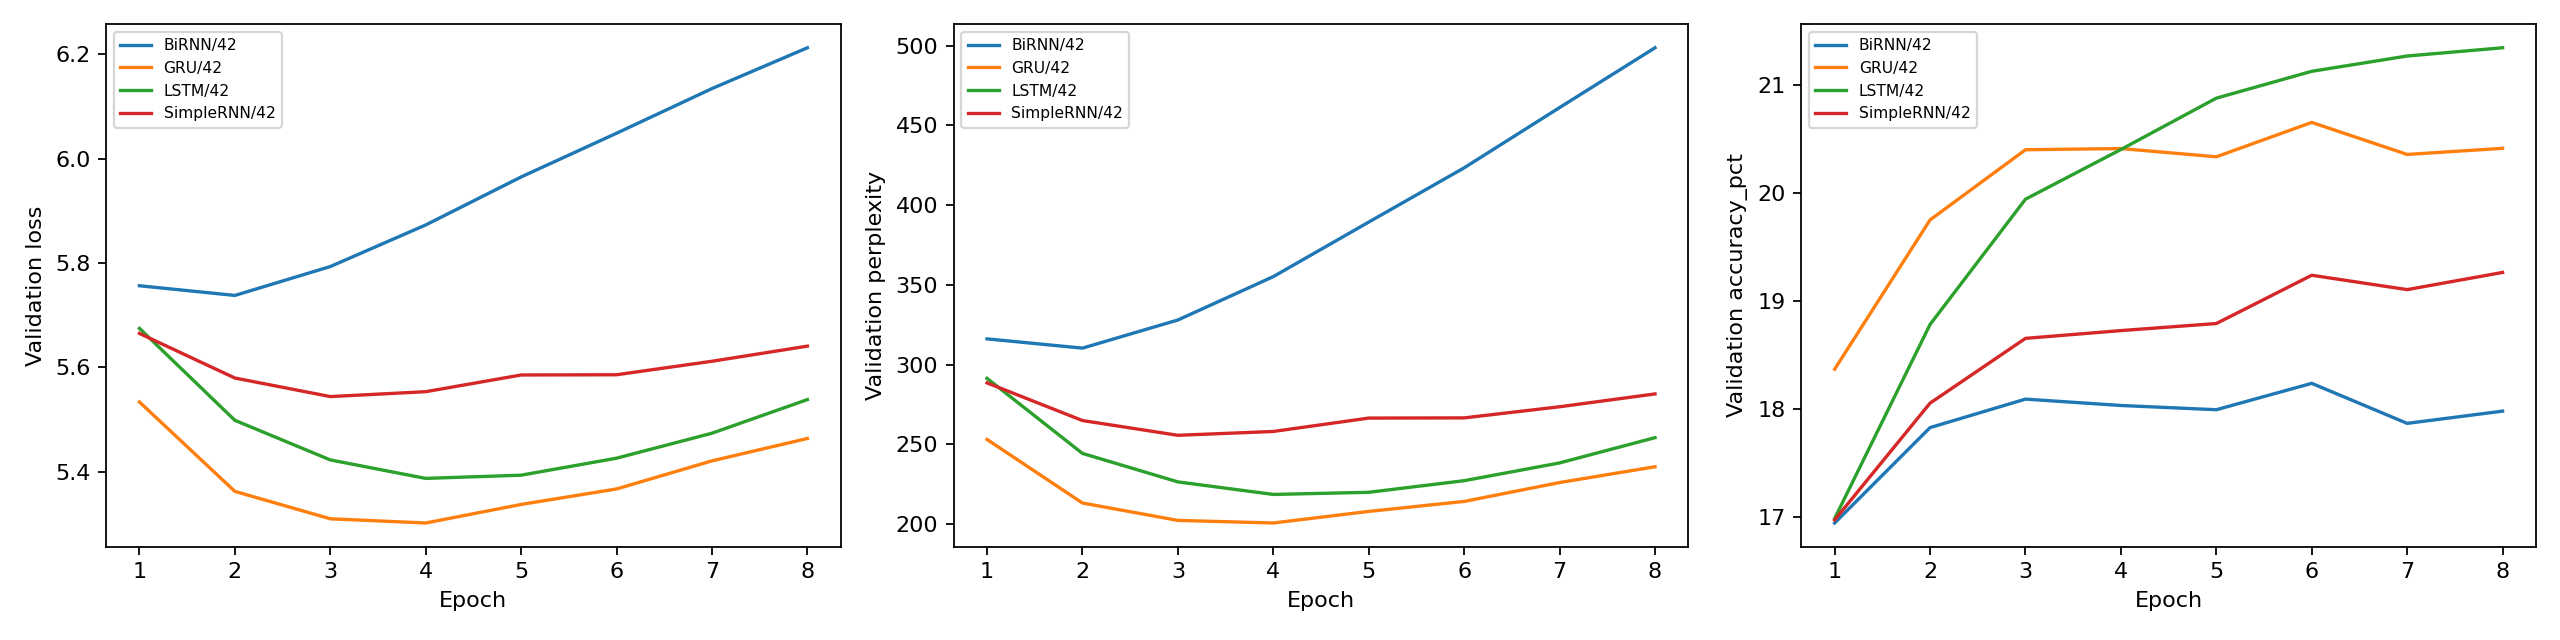

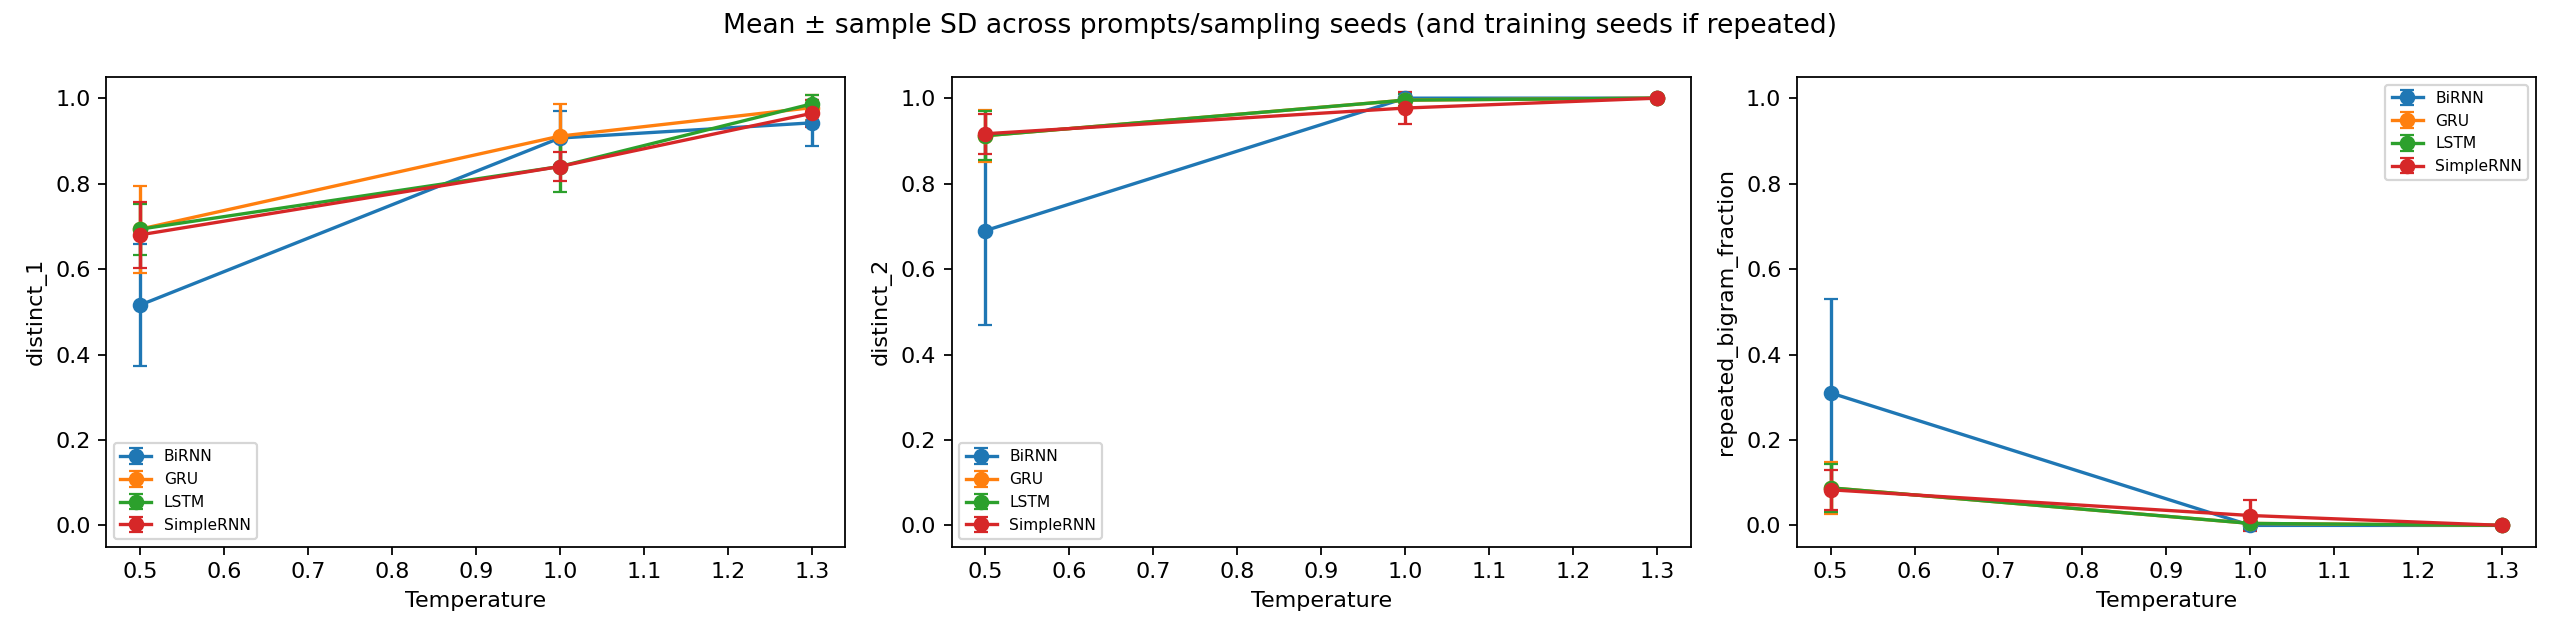

In [6]:
results = run(CONFIG, OUTPUT)
display(results)
display(pd.read_csv(OUTPUT / 'temperature_summary.csv'))
from IPython.display import Image, display, FileLink
display(Image(filename=str(OUTPUT / 'learning_curves.png')))
display(Image(filename=str(OUTPUT / 'temperature_metrics.png')))


## Generated continuations and diversity

I save the prompt and continuation separately, with sample ID, model, checkpoint, training seed, sampling seed and temperature. Each continuation has 25 tokens. I calculate distinct-1/TTR, distinct-2 and repeated-bigram fraction on the continuation only. Distinct-2 and repeated-bigram fraction are complements, not independent evidence. Error bars show descriptive sample standard deviation across prompts and sampling seeds, and across training seeds if repeated. They are not confidence intervals. I assess coherence and contextual consistency from the actual text.

In [7]:
samples = pd.read_csv(OUTPUT / 'samples.csv')
for row in samples.itertuples(index=False):
    print(f'\n{row.sample_id}\nPROMPT: {row.prompt}\nCONTINUATION: {row.continuation}')



SimpleRNN-train42-p1-t0.5-s101
PROMPT: the history of the united states began with
CONTINUATION: the same in the spring . the end of the state of the song was replaced . the first time , he was established on

SimpleRNN-train42-p1-t0.5-s202
PROMPT: the history of the united states began with
CONTINUATION: the polish time . the song was not cause that the band was not three than the original war . the british fleet was the

SimpleRNN-train42-p1-t0.5-s303
PROMPT: the history of the united states began with
CONTINUATION: the center of the 3rd end of the top . the band debuted , the international state was became the most of the table .

SimpleRNN-train42-p1-t1.0-s101
PROMPT: the history of the united states began with
CONTINUATION: the names in the spring . while end was offered on loan 2 to new antarctic . the first half , is christmas , the

SimpleRNN-train42-p1-t1.0-s202
PROMPT: the history of the united states began with
CONTINUATION: female s time . james won one of the act is used 

## Initial results and discussion

My initial final-epoch validation perplexities were 284.42 for SimpleRNN, 478.23 for BiRNN, 259.37 for LSTM and 235.37 for GRU. The best logged values were respectively 256.10 at epoch 4, 305.41 at epoch 2, 222.02 at epoch 4 and 201.91 at epoch 4. All four deteriorated after their best validation epoch. Those measurements used a validation loader that dropped the final partial batch; reported runtime included validation without explicit CUDA synchronization. They are not results of the revised implementation above.

I select GRU for the initial experiment because of its lowest validation perplexity and lower reported fit time than LSTM. LSTM achieved higher final accuracy, and SimpleRNN was faster. None showed reliable sustained coherence. The repository README contains the complete comparison across four models and three temperatures, with full samples in `results/initial_run/`.

For example, LSTM sample `legacy-019` describes an army as “certified platinum”, showing topic drift, while GRU `legacy-022` repeats “infantry”. SimpleRNN `legacy-001` shifts history toward Billboard music, and BiRNN `legacy-018` mixes war with sport. Locally familiar phrases do not establish sustained coherence. SimpleRNN prompt 1's original TTR is 0.818 → 0.939 → 0.879 across temperatures, so diversity does not increase for every individual sample.

I do not infer calibration from perplexity or coherence from diversity and accuracy. The experiment does not isolate vanishing gradients or larger BiRNN capacity as causes of the ranking. I will reassess the model choice using revised best-checkpoint scores, generated text and runtime after Kaggle execution. Revised qualitative conclusions remain pending.

## Exporting the experiment

Each completed run exports results, JSON/CSV history, configuration, environment, vocabulary, dataset statistics, full samples, temperature summaries, plots and a quantitative README. I retain the executed notebook separately. The ZIP excludes large checkpoints, which are available as separate downloads below.

The generated results README contains measured tables; I complete the qualitative interpretation after reviewing the actual samples. Re-running `export(OUTPUT)` rebuilds that file from saved CSVs. My separate Word/PDF submission includes my student details, assignment title, system title, dataset link and repository link.

In [10]:
display(FileLink(str(OUTPUT / 'submission_artifacts.zip')))
print('Best checkpoints (download separately):')
for checkpoint in sorted(OUTPUT.glob('*-best.pt')):
    display(FileLink(str(checkpoint)))


/kaggle/working/revised_results/submission_artifacts.zip

Best checkpoints (download separately):


/kaggle/working/revised_results/BiRNN-seed42-best.pt

/kaggle/working/revised_results/GRU-seed42-best.pt

/kaggle/working/revised_results/LSTM-seed42-best.pt

/kaggle/working/revised_results/SimpleRNN-seed42-best.pt